# Beyond the classical interpolators

The classical interpolators, kriging above all, describe a field by its second order, how alike two
values are at a given separation. On fields that the second order describes well they are hard to beat,
and an ensemble should match them there. Many fields carry their meaning beyond pairs, in channels whose
high values connect, in patches with sharp edges, in a skewed law. This tutorial sets Spatialize beside
SciPy's interpolation, inverse distance weighting and kriging from PyKrige, first on two fields of the
first kind, then on two of the second, each method with the settings cross-validation prefers.

## Learning goals

- How to give each interpolator, Spatialize included, the settings cross-validation prefers.
- How Spatialize compares with the classical interpolators where the second order describes the field.
- How it compares where the field's structure lies beyond pairs, in connected channels and sharp patches.
- What a map keeps of that structure, measured by the high-value regions it recovers and their
  connections.

*What can an ensemble do that the second order cannot?*

## The idea

Kriging predicts each value as a weighted sum of the data, with weights from the covariance, so two fields
with the same covariance get the same weights whatever else they hold. That suits a Gaussian field, which
its covariance describes completely. It leaves out what three or more locations do together, whether high
values string into channels, where a patch ends, how a skewed variable clusters. An ensemble reads the
data through the cells of random partitions, which group many locations at once, so its estimate can
follow such structure without a model of it. The book behind Spatialize develops the argument, which the
tutorial *Pairs are not enough* shows on its own.

Each method here chooses its settings by five-fold cross-validation on the data alone, as a user without
the truth would. SciPy chooses among nearest, linear and cubic interpolation. Inverse distance chooses
its exponent and search radius. PyKrige chooses the variogram model, fitted to the experimental
variogram, and the number of neighbours of ordinary kriging. Spatialize chooses the decoder, the
partition and the granularity at the knee of its Pareto search, then the mean or the median of its
members. The truth then judges each map, on the nodes every method predicts, since SciPy leaves the nodes
outside the triangulation of the data without a value.

## Step by step

### The interpolators and their settings

One function per method chooses its settings on the data and returns a function that predicts with them.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pykrige.rk import Krige
from scipy import ndimage
from sklearn.model_selection import GridSearchCV

import spatialize
from spatialize.data import load_simulated_anisotropic_data, load_elevation_walker_lake
from spatialize.evaluation import SuppressOutput, scipy_prediction, kriging_prediction
from spatialize.gs.esi import esi_nongriddata, esi_pareto_hparams_search
from spatialize.gs.idw import idw_hparams_search, idw_nongriddata
import spatialize.gs.esi.scorefunction as sf

spatialize.session.set(empty_cells="coarsen", progress=False)
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)

def kfold(points, values, predict, k=5, held_out=False):
    # five-fold predictions of every datum; their mean absolute error, or the predictions themselves
    folds = np.random.default_rng(0).permutation(len(values)) % k
    predictions = np.full(len(values), np.nan)
    for f in range(k):
        test = folds == f
        predictions[test] = np.asarray(predict(points[~test], values[~test], points[test]), dtype=float)
    return predictions if held_out else np.nanmean(np.abs(predictions - values))

def choose(points, values):
    chosen, notes = {}, {}
    span = np.ptp(points, axis=0).max()

    method = min(("nearest", "linear", "cubic"),
                 key=lambda m: kfold(points, values, lambda p, v, x: scipy_prediction(p, v, x, method=m)))
    chosen["SciPy"] = lambda p, v, x, m=method: scipy_prediction(p, v, x, method=m)
    notes["SciPy"] = f"{method} interpolation"

    best = idw_hparams_search(points, values, points[:10], k=5, folding_seed=0,
                              radius=(0.1 * span, 0.2 * span, 0.5 * span, np.inf), exponent=(1.0, 1.5, 2.0, 3.0)).best_result()
    chosen["inverse distance"] = lambda p, v, x, b=best: idw_nongriddata(p, v, x, best_params_found=b).estimation()
    notes["inverse distance"] = f"exponent {best['exponent']}, radius {best['radius']:.3g}"

    search = GridSearchCV(Krige(), {"variogram_model": ["spherical", "exponential", "gaussian"], "nlags": [8],
                                    "n_closest_points": [10, 20], "method": ["ordinary"]},
                          scoring="neg_mean_absolute_error", cv=5)
    with SuppressOutput():
        params = search.fit(points, values).best_params_
    chosen["PyKrige"] = lambda p, v, x, k=params: kriging_prediction(p, v, x, **k)
    notes["PyKrige"] = f"ordinary, {params['variogram_model']} variogram, {params['n_closest_points']} neighbours"

    best, best_error = None, np.inf
    variogram = dict(model=["spherical", "exponential", "gaussian"], nugget=[0.0],
                     range=list(span * np.array([0.07, 0.17, 0.33, 0.67])), sill=[1.0])
    for p_process, decoder in (("mondrian", "adaptiveidw"), ("mondrian", "sharpidw"), ("mondrian", "kriging"),
                               ("voronoi", "sharpidw")):
        options = variogram if decoder == "kriging" else {}
        knee = esi_pareto_hparams_search(points, values, local_interpolator=decoder, p_process=p_process, n_partitions=[100],
                                         alpha=[0.8, 0.9, 0.95, 0.98], k=5, scoring=sf.mae, seed=0, **options).best_result(strategy="knee")
        if knee["decoder_error"] < best_error:
            best = dict(local_interpolator=decoder, p_process=p_process, alpha=knee["alpha"], **{key: knee[key] for key in options})
            best_error = knee["decoder_error"]
    readings = {"mean": lambda m: m.mean(axis=1), "median": lambda m: np.median(m, axis=1)}
    predictor = lambda r: (lambda p, v, x, b=best: readings[r](esi_nongriddata(p, v, x, n_partitions=200, seed=0, **b).esi_samples()))
    reading = min(readings, key=lambda r: kfold(points, values, predictor(r)))
    chosen["Spatialize"] = predictor(reading)
    notes["Spatialize"] = f"{best['p_process']}, {best['local_interpolator']}, alpha {best['alpha']}, {reading} of the members"
    return chosen, notes

def compare(name, f, region=None):
    start = time.perf_counter()
    chosen, notes = choose(f["points"], f["values"])
    maps = {m: np.asarray(predict(f["points"], f["values"], f["xi"]), dtype=float) for m, predict in chosen.items()}
    nodes = np.all([~np.isnan(z) for z in maps.values()], axis=0)
    rows = {}
    for m, z in maps.items():
        rows[m] = {"settings": notes[m], "MAE against the truth": np.abs(z - f["truth"])[nodes].mean(),
                   "share of the map without a value": np.mean(np.isnan(z))}
        if region is not None:                      # the high-value region the map recovers, and its pieces
            high = np.nan_to_num(z, nan=-np.inf) > region["threshold"]
            rows[m]["overlap with the true high region"] = (high & region["mask"]).sum() / (high | region["mask"]).sum()
            rows[m]["pieces of the high region"] = ndimage.label(high.reshape(f["shape"]))[1]
    print(f"{name}: {time.perf_counter() - start:.0f} s")
    return maps, notes, pd.DataFrame(rows).T

def show(name, f, maps, notes, region=None):
    fig, axes = plt.subplots(1, 5, figsize=(25, 4.8))
    lo, hi = np.nanpercentile(f["truth"], [1, 99])
    for ax, (title, z) in zip(axes, [("truth", f["truth"])] + list(maps.items())):
        ax.imshow(z.reshape(f["shape"]).T, origin="lower", cmap="viridis", vmin=lo, vmax=hi)
        if region is not None:
            ax.contour((np.nan_to_num(z, nan=-np.inf) > region["threshold"]).reshape(f["shape"]).T.astype(float),
                       levels=[0.5], colors="white", linewidths=0.6)
        ax.set_title(f"{name}, truth" if title == "truth" else f"{title}\n{notes[title]}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    plt.show()

### Fields the second order describes

The first field is the anisotropic Gaussian simulation used across this gallery, 400 data on a 200 × 200
grid read on every second node, a field its covariance describes completely. The second is the elevation
around Walker Lake, Nevada, from the U.S. Geological Survey, 780 data on a 260 × 300 grid of 0.1 km cells
read on every second node, a smooth real surface with a flat lake and steep ranges.

In [2]:
(samples, _), _, _, grid = load_simulated_anisotropic_data()
g = np.arange(0.0, 200.0, 2.0)
fields = {"anisotropic field": dict(points=samples[["x", "y"]].values, values=samples["sim1"].values,
                                    xi=np.stack(np.meshgrid(g, g, indexing="ij"), -1).reshape(-1, 2),
                                    truth=grid["sim1"].values.reshape(200, 200).T[::2, ::2].ravel(), shape=(100, 100))}
wl_samples, wl_grid = load_elevation_walker_lake()
xs, ys = np.sort(wl_grid["x"].unique())[::2], np.sort(wl_grid["y"].unique())[::2]
fields["Walker Lake"] = dict(points=wl_samples[["x", "y"]].values, values=wl_samples["elevation"].values,
                             xi=np.stack(np.meshgrid(xs, ys, indexing="ij"), -1).reshape(-1, 2),
                             truth=wl_grid["elevation"].values.reshape(300, 260)[::2, ::2].T.ravel(), shape=(len(xs), len(ys)))
results, all_maps, all_notes = {}, {}, {}
for name, f in fields.items():
    all_maps[name], all_notes[name], results[name] = compare(name, f)
pd.concat(results).infer_objects().round(3)

anisotropic field: 37 s
Walker Lake: 84 s


settings  \
anisotropic field SciPy                                             linear interpolation   
                  inverse distance                             exponent 3.0, radius 99.5   
                  PyKrige                   ordinary, spherical variogram, 10 neighbours   
                  Spatialize          mondrian, kriging, alpha 0.95, mean of the members   
Walker Lake       SciPy                                              cubic interpolation   
                  inverse distance                             exponent 3.0, radius 2.99   
                  PyKrige                 ordinary, exponential variogram, 20 neighbours   
                  Spatialize        mondrian, kriging, alpha 0.95, median of the members   

                                    MAE against the truth  \
anisotropic field SciPy                             0.477   
                  inverse distance                  0.471   
                  PyKrige                           0.487   
                  Spatialize                        0.448   
Walker Lake       SciPy                            27.337   
                  inverse distance                 47.863   
                  PyKrige                          29.307   
                  Spatialize                       29.465   

                                    share of the map without a value  
anisotropic field SciPy                                        0.035  
                  inverse distance                             0.000  
                  PyKrige                                      0.000  
                  Spatialize                                   0.000  
Walker Lake       SciPy                                        0.022  
                  inverse distance                             0.000  
                  PyKrige                                      0.000  
                  Spatialize                                   0.000

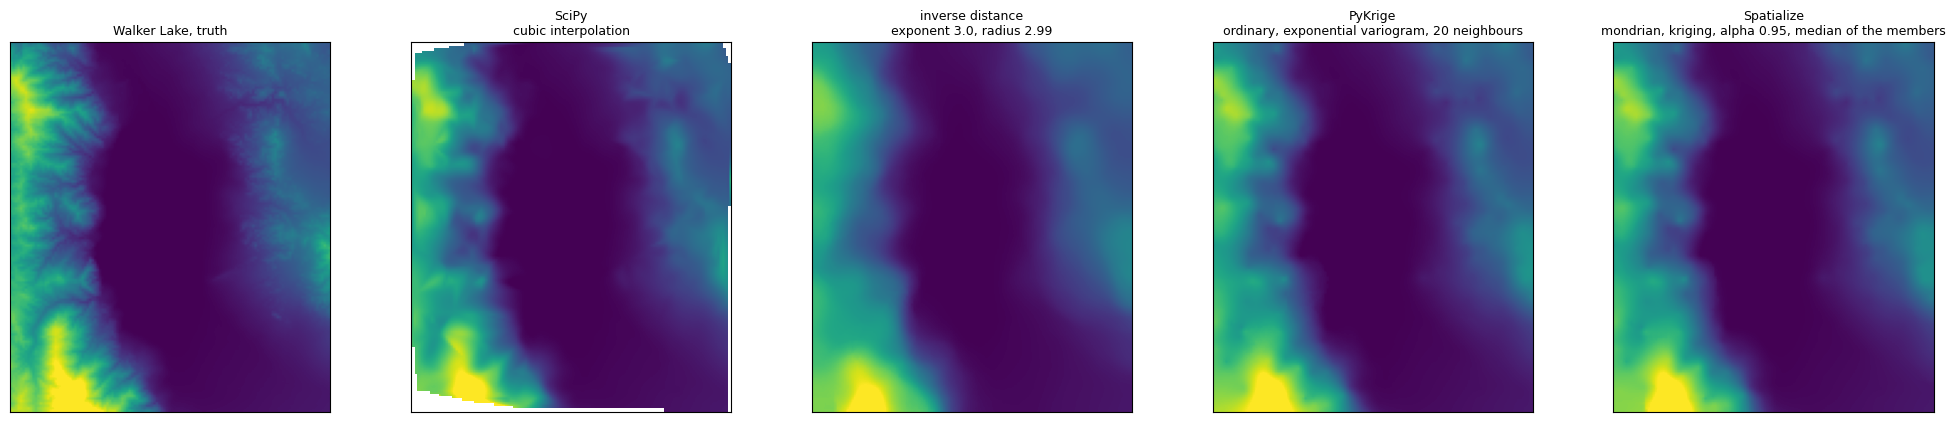

In [3]:
show("Walker Lake", fields["Walker Lake"], all_maps["Walker Lake"], all_notes["Walker Lake"])

Where the second order describes the field, Spatialize stands with the classical interpolators. On the
Gaussian field, which its covariance describes completely, it gives the best map, an error of 0.448
against 0.471 to 0.487, with its kriging decoder. On Walker Lake it matches kriging, 29.5 m against
29.3 m, while SciPy's cubic interpolation over the triangulation does best, 27.3 m, on the 98 % of the
map it covers. The maps keep the lake and the two ranges alike.

### Fields beyond the second order

The third field holds four sinuous channels of high values across a low background, as rivers, veins or
roads do, with a skewed law on each side. A use of it asks whether the high values connect. The
fourth is a mosaic of 60 patches, each with its own value from a heavy-tailed law, as soil types, parcels
or geological units have, where a use asks where each patch ends. Both are read at 400 locations on
a 100 × 100 grid. Besides the error, we measure the overlap of each map's high region with the true one
and the number of pieces it breaks into.

In [4]:
n = 100
cells = (np.arange(n) + 0.5) / n
X, Y = np.meshgrid(cells, cells, indexing="ij")
nodes = np.stack([X.ravel(), Y.ravel()], -1)

def channels(seed):
    rng = np.random.default_rng(seed)
    inside = np.zeros((n, n), bool)
    for _ in range(4):
        centre, amplitude, wavelength = rng.uniform(.1, .9), rng.uniform(.04, .12), rng.uniform(.3, .7)
        phase, width = rng.uniform(0, 6.3), rng.uniform(.025, .04)
        inside |= np.abs(Y - (centre + amplitude * np.sin(2 * np.pi * X / wavelength + phase))) < width
    values = np.where(inside, rng.lognormal(1.0, 0.25, (n, n)), rng.lognormal(-0.5, 0.25, (n, n)))
    return values.ravel(), inside.ravel()

def mosaic(seed):
    rng = np.random.default_rng(seed)
    nuclei, marks = rng.random((60, 2)), rng.lognormal(0.0, 1.0, 60)
    patch = np.argmin(((nodes[:, None] - nuclei[None]) ** 2).sum(-1), axis=1)
    values = marks[patch] * rng.lognormal(0.0, 0.1, len(nodes))
    return values, marks[patch] > np.quantile(marks[patch], 0.8)

beyond, regions = {}, {}
for name, (truth, mask) in (("channels", channels(0)), ("mosaic", mosaic(0))):
    pick = np.random.default_rng(1).choice(len(nodes), 400, replace=False)
    beyond[name] = dict(points=nodes[pick], values=truth[pick], xi=nodes, truth=truth, shape=(n, n))
    threshold = (np.median(truth[mask]) + np.median(truth[~mask])) / 2 if name == "channels" else np.quantile(truth, 0.8)
    regions[name] = dict(mask=mask, threshold=threshold)
for name in beyond:
    print(f"{name}: the true high region in {ndimage.label(regions[name]['mask'].reshape(n, n))[1]} pieces")
results2 = {}
for name, f in beyond.items():
    all_maps[name], all_notes[name], results2[name] = compare(name, f, regions[name])
pd.concat(results2).infer_objects().round(3)

channels: the true high region in 2 pieces
mosaic: the true high region in 8 pieces
channels: 59 s
mosaic: 34 s


settings  \
channels SciPy                                                linear interpolation   
         inverse distance                               exponent 1.0, radius 0.099   
         PyKrige                      ordinary, spherical variogram, 10 neighbours   
         Spatialize        mondrian, adaptiveidw, alpha 0.9, median of the members   
mosaic   SciPy                                                linear interpolation   
         inverse distance                               exponent 1.0, radius 0.099   
         PyKrige                    ordinary, exponential variogram, 10 neighbours   
         Spatialize           mondrian, kriging, alpha 0.95, median of the members   

                           MAE against the truth  \
channels SciPy                             0.536   
         inverse distance                  0.671   
         PyKrige                           0.618   
         Spatialize                        0.478   
mosaic   SciPy                             0.405   
         inverse distance                  0.603   
         PyKrige                           0.527   
         Spatialize                        0.380   

                           share of the map without a value  \
channels SciPy                                        0.048   
         inverse distance                             0.000   
         PyKrige                                      0.000   
         Spatialize                                   0.000   
mosaic   SciPy                                        0.048   
         inverse distance                             0.000   
         PyKrige                                      0.000   
         Spatialize                                   0.000   

                           overlap with the true high region  \
channels SciPy                                         0.565   
         inverse distance                              0.395   
         PyKrige                                       0.469   
         Spatialize                                    0.630   
mosaic   SciPy                                         0.541   
         inverse distance                              0.329   
         PyKrige                                       0.366   
         Spatialize                                    0.583   

                           pieces of the high region  
channels SciPy                                     7  
         inverse distance                         22  
         PyKrige                                  25  
         Spatialize                                9  
mosaic   SciPy                                    12  
         inverse distance                         10  
         PyKrige                                  32  
         Spatialize                               11

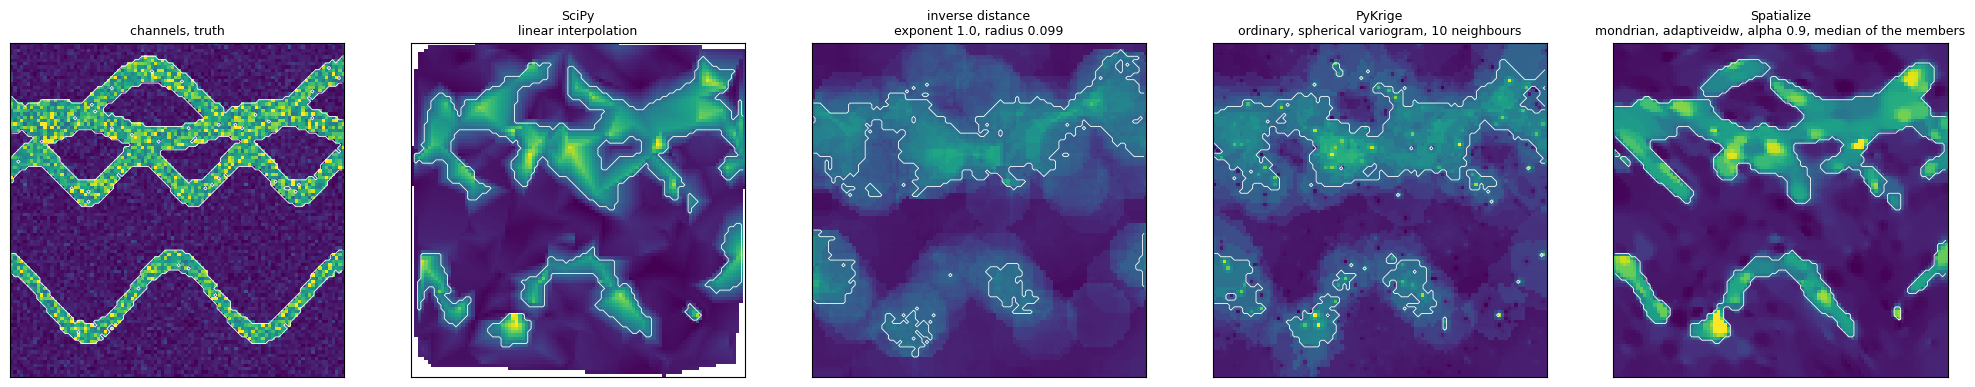

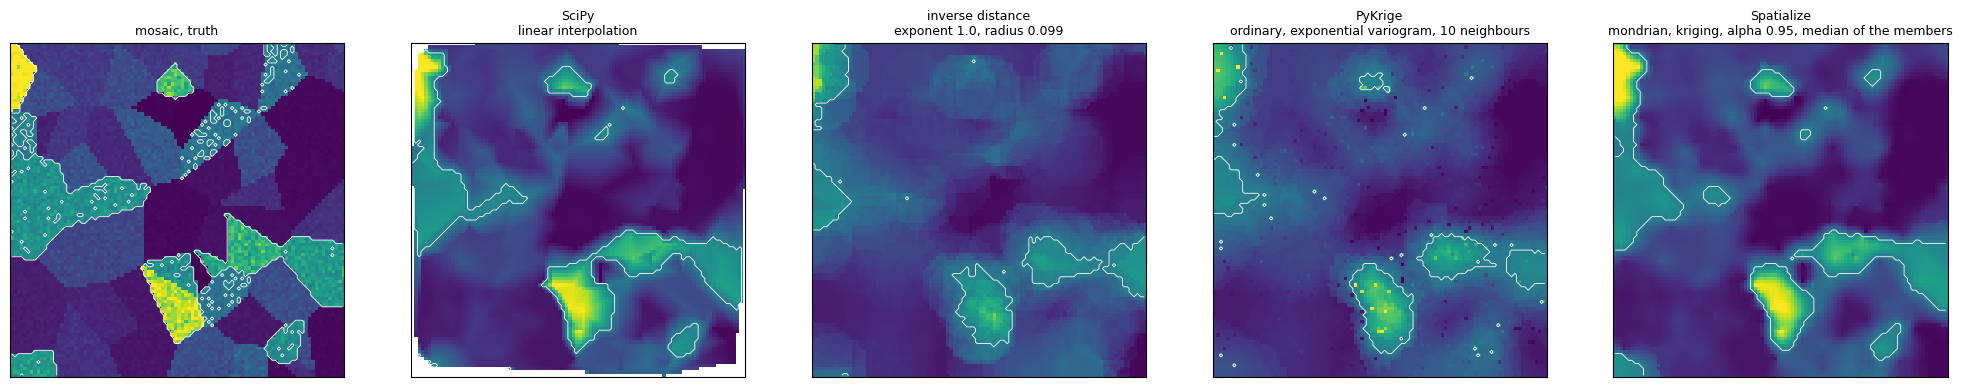

In [5]:
for name, f in beyond.items():
    show(name, f, all_maps[name], all_notes[name], regions[name])

Beyond the second order the gap opens. On the channels Spatialize's error is 0.478 against 0.618 for
kriging, 23 % lower, and its high region overlaps the true channels at 0.63 against 0.47. Kriging breaks
the two channels into 25 pieces of blurred patches, while Spatialize draws them as sinuous bodies, in 9
pieces where the sample left gaps. SciPy's linear interpolation keeps fewer pieces, 7, while drawing
straight-sided shapes and leaving 5 % of the map empty. On the mosaic Spatialize's error is 0.380 against
0.527 for kriging, 28 % lower, and its map keeps the edges of the high patches, which kriging rounds off.
In both fields Spatialize chose the median of its members, a reading that holds a sharp edge where an
average smears it.

## Pitfalls

- **Spatialize with its defaults against tuned rivals.** Give it the Pareto search, as here, with the
  decoders that suit the field. A default granularity can lose to a tuned kriging for no reason of the
  method.
- **The error alone on a field with structure.** Two maps can differ little in mean absolute error while
  one breaks a channel the other keeps. Measure what the use needs, a connected region, an area above a
  limit, an edge.
- **The mean of the members on a skewed field.** Their median can follow sharp edges and heavy tails
  better. Choose the reading by cross-validation, as here.
- **An isotropic decoder on a field with a direction.** Compare the adaptive decoders there, which fit a
  direction in each cell.

## Try it yourself

1. Narrow the channels (`width` between 0.015 and 0.025) and count the pieces again.
2. Repeat on Walker Lake with 300 data (`load_elevation_walker_lake(n_samples=300)`).
3. Add the drawing decoders to Spatialize's candidates and read the probability of the high region.

## Next

- *Pairs are not enough*, for the theory behind fields beyond the second order.
- *Choosing an ensemble with the Pareto search*, for the knee.
- *Heavy tails* and *A non-stationary field*, for two more fields where the second order falls short.
- The documentation's [Evaluation](https://spatialize.readthedocs.io/en/latest/reference/evaluation.html)
  (reference).